# Used-Car Price Prediction: Final ML Engine (Random Forest)

**ICS 3202: Artificial Intelligence Project Deliverable 3**

This notebook contains the complete logic of the final machine learning engine used in our mobile app. A user enters the details of a used car and the engine predicts a fair price together with an explanation of why it predicted that price.

The notebook follows all stages of the data mining process:

1. **Problem understanding**: what are we predicting and why?
2. **Data understanding and cleaning**: load the data, check its quality and fix problems.
3. **Exploratory data analysis (EDA)**: look for patterns with charts and statistics.
4. **Data preparation**: turn the data into a form the algorithms can use and split it for fair testing.
5. **Base model**: a simple Linear Regression to set a benchmark.
6. **Final model**: a Random Forest tuned and compared fairly against the base model.
7. **Validation**: check that the results are reliable and the model is not just memorising.
8. **Explainability**: show which inputs drive the price globally and for a single car.
9. **Input checking and sensitivity**: how the engine reacts to different and invalid inputs.
10. **Saving the engine** for the mobile app to use.


## 1. Problem understanding

The problem at hand is that buyers and sellers of used cars often do not know what a fair price is. Prices depend on many things at once age, mileage, brand, engine and more which is hard to predict by eye.

The goal is to therefore build a model that takes a car's details and predicts its price.

**Type of machine learning:** We are predicting price which is a number so this is a regression problem where the model learns from past examples where the correct price is already known.

We use three standard measures for regression:

| Measure | What it tells us | Better is |
|---|---|---|
| **MAE** (Mean Absolute Error) | On average, how far off the predicted price is, in price units | Lower |
| **RMSE** (Root Mean Squared Error) | Like MAE, but punishes large mistakes more | Lower |
| **R²** (R-squared) | The share of the variation in prices the model explains (1.0 = perfect, 0 = no better than guessing the average) | Higher |

In [2]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42                      # makes results repeatable
DATA_PATH = "car_price_dataset.csv"    # change this if the file is in another folder

## 2. Data understanding and cleaning

We start by loading the dataset and looking at its size, columns and data types. Each row is one used car.

In [3]:
df = pd.read_csv(r"C:\Users\mugoy\Downloads\carsales datasales\car_price_dataset.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (2000, 11)


,Car_ID,Brand,Model_Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Horsepower,Price
0,1,Ford,2023,1.2,Hybrid,Manual,180635,4,3,82,34309.25
1,2,Hyundai,2018,3.2,Electric,Manual,35628,2,4,259,55153.60
2,3,BMW,2008,2.2,Diesel,Manual,74672,3,2,333,41894.40
3,4,Hyundai,2017,2.2,Petrol,Automatic,51246,4,4,381,54046.70
4,5,Hyundai,2012,2.4,Electric,Manual,147233,3,4,290,38010.35


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car_ID        2000 non-null   int64  
 1   Brand         2000 non-null   str    
 2   Model_Year    2000 non-null   int64  
 3   Engine_Size   2000 non-null   float64
 4   Fuel_Type     2000 non-null   str    
 5   Transmission  2000 non-null   str    
 6   Mileage       2000 non-null   int64  
 7   Doors         2000 non-null   int64  
 8   Owner_Count   2000 non-null   int64  
 9   Horsepower    2000 non-null   int64  
 10  Price         2000 non-null   float64
dtypes: float64(2), int64(6), str(3)
memory usage: 172.0 KB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_ID,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
Brand,2000,6,Toyota,352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model_Year,2000.0,NaN,NaN,NaN,2013.963,5.508248,2005.0,2009.0,2014.0,2019.0,2023.0
Engine_Size,2000.0,NaN,NaN,NaN,2.96755,1.146926,1.0,2.0,2.9,4.0,5.0
Fuel_Type,2000,4,Diesel,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,2000,2,Automatic,1018,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mileage,2000.0,NaN,NaN,NaN,100736.9565,56002.915221,5036.0,52365.5,100590.5,148024.5,199904.0
Doors,2000.0,NaN,NaN,NaN,2.988,0.818041,2.0,2.0,3.0,4.0,4.0
Owner_Count,2000.0,NaN,NaN,NaN,2.5325,1.125423,1.0,2.0,3.0,4.0,4.0
Horsepower,2000.0,NaN,NaN,NaN,235.7095,95.59811,70.0,154.0,236.0,319.0,399.0


### Data quality checks

Before modelling we checked for three common problems:

- Empty cells that a model cannot use.
- The same record repeated, which can make results look better than they are.
- Columns like `Car_ID` only label each row and carry no information about price. If left in, a model might wrongly treat them as meaningful.

In [7]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

# 1) drop the identifier column (it only labels rows)
if "Car_ID" in df.columns:
    df = df.drop(columns="Car_ID")

# 2) remove exact duplicates
df = df.drop_duplicates()

# 3) tidy text columns (remove accidental spaces) and fill any gaps
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].astype(str).str.strip()
        if df[col].isin(["nan", "None", ""]).any():
            df[col] = df[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})
            df[col] = df[col].fillna(df[col].mode()[0])          # most common value
    else:
        df[col] = df[col].fillna(df[col].median())              # middle value

print("\nShape after cleaning:", df.shape)

Missing values per column:
Brand           0
Model_Year      0
Engine_Size     0
Fuel_Type       0
Transmission    0
Mileage         0
Doors           0
Owner_Count     0
Horsepower      0
Price           0
dtype: int64

Duplicate rows: 0

Shape after cleaning: (2000, 10)


### Checking for impossible values

Even without missing values, data can contain values that make no sense (for example a negative mileage). We test a few rules and drop any rows that break them.

In [8]:
this_year = pd.Timestamp.now().year
rules = {
    "Price must be above 0": ("Price", lambda s: s <= 0),
    "Mileage cannot be negative": ("Mileage", lambda s: s < 0),
    "Engine size must be above 0": ("Engine_Size", lambda s: s <= 0),
    "Model year cannot be in the far future": ("Model_Year", lambda s: s > this_year + 1),
}

bad_rows = pd.Series(False, index=df.index)
for message, (col, is_bad) in rules.items():
    if col in df.columns:
        n_bad = int(is_bad(df[col]).sum())
        print(f"{message}: {n_bad} rows break this rule")
        bad_rows |= is_bad(df[col])

df = df[~bad_rows].reset_index(drop=True)
print("\nRows kept:", len(df))

Price must be above 0: 0 rows break this rule
Mileage cannot be negative: 0 rows break this rule
Engine size must be above 0: 0 rows break this rule
Model year cannot be in the far future: 0 rows break this rule

Rows kept: 2000


### Outliers

These are values that tend to be far apart from other values. We use the IQR rule a value is flagged if it is more than 1.5 times the interquartile range beyond the quartiles. We only *count* outliers here. Random Forests are not thrown off by extreme values, and genuine expensive or very old cars are real cases the app should handle, so we keep them.

In [9]:
numeric_cols = df.select_dtypes(include="number").columns
rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append({"Column": col, "Outliers flagged": n_out, "Share of rows": f"{n_out / len(df):.1%}"})
pd.DataFrame(rows)

,Column,Outliers flagged,Share of rows
0,Model_Year,0,0.0%
1,Engine_Size,0,0.0%
2,Mileage,0,0.0%
3,Doors,0,0.0%
4,Owner_Count,0,0.0%
5,Horsepower,0,0.0%
6,Price,2,0.1%


## 3. Exploratory data analysis (EDA)

EDA means looking at the data with charts and simple statistics to understand patterns modelling. The observations below are calculated directly from the data.

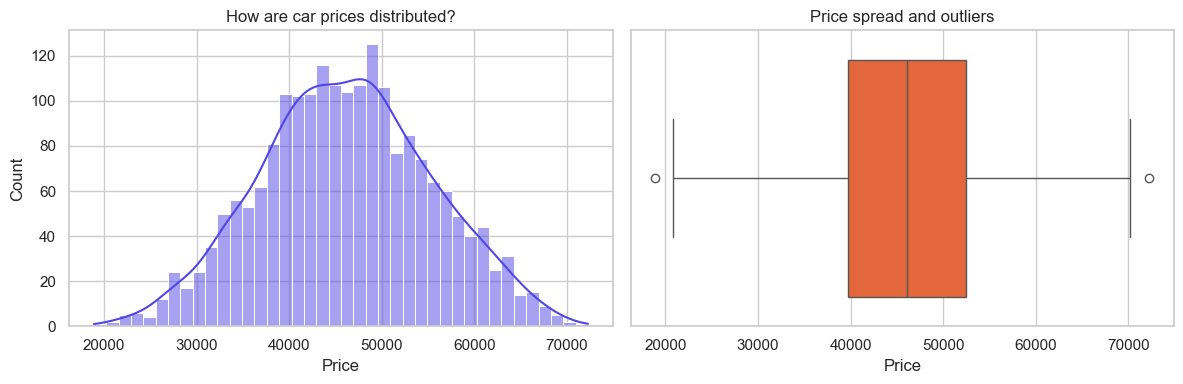

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], bins=40, kde=True, ax=axes[0], color="#4F46E5")
axes[0].set_title("How are car prices distributed?")
sns.boxplot(x=df["Price"], ax=axes[1], color="#FF5A1F")
axes[1].set_title("Price spread and outliers")
plt.tight_layout()
plt.show()

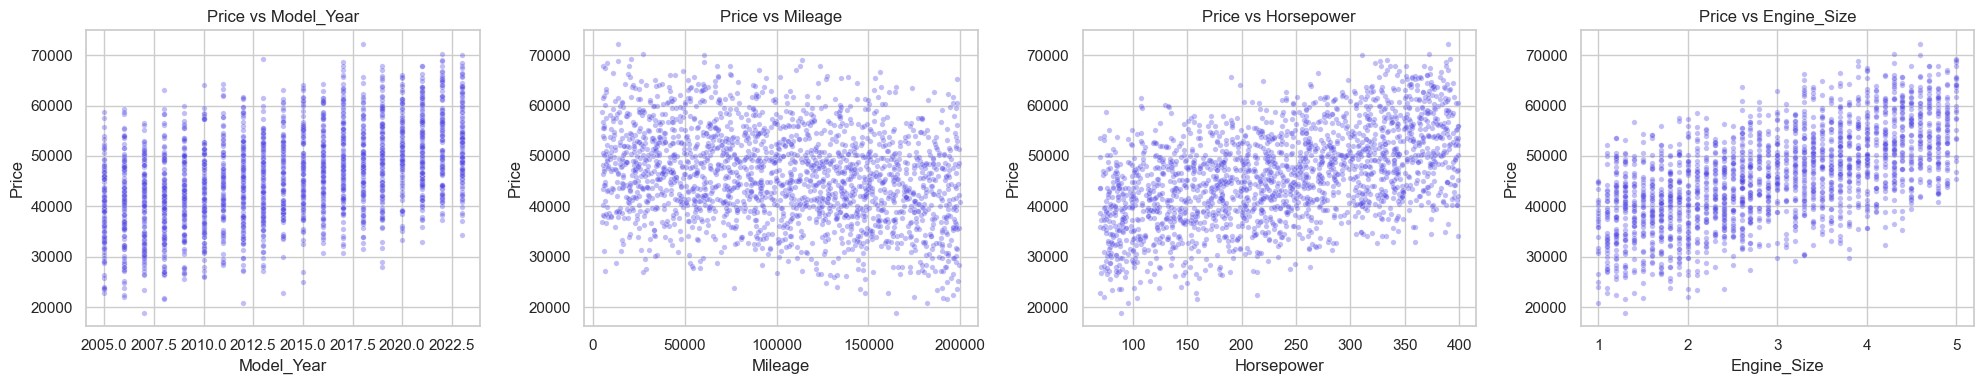

In [11]:
num_features = [c for c in df.select_dtypes(include="number").columns if c != "Price"]
cols_to_plot = [c for c in ["Model_Year", "Mileage", "Horsepower", "Engine_Size"] if c in num_features]

fig, axes = plt.subplots(1, len(cols_to_plot), figsize=(5 * len(cols_to_plot), 4))
for ax, col in zip(np.atleast_1d(axes), cols_to_plot):
    sns.scatterplot(data=df, x=col, y="Price", alpha=0.35, s=15, ax=ax, color="#4F46E5")
    ax.set_title(f"Price vs {col}")
plt.tight_layout()
plt.show()

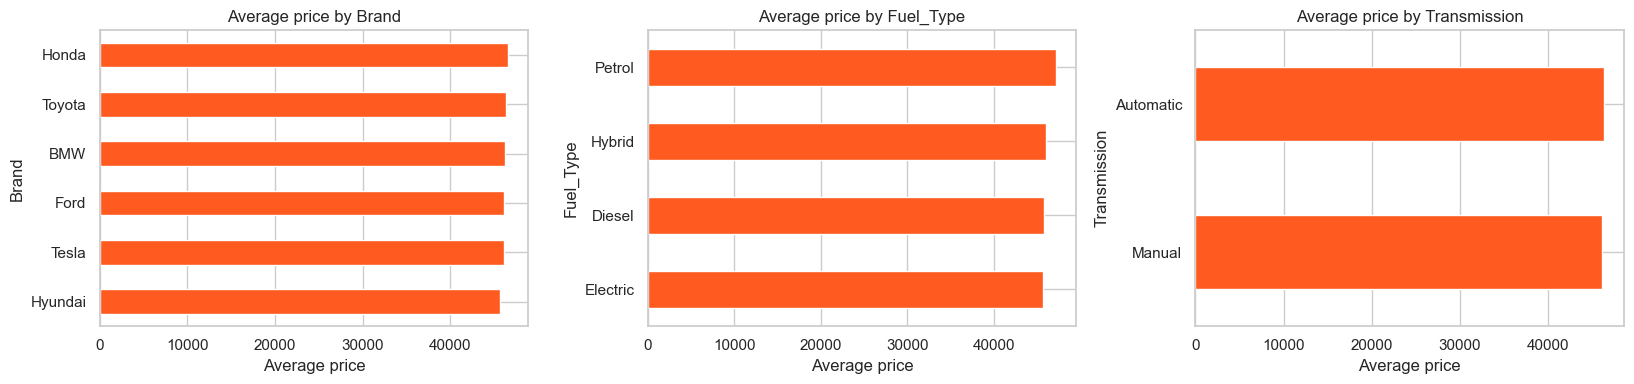

In [12]:
cat_features = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]

fig, axes = plt.subplots(1, len(cat_features), figsize=(5.5 * len(cat_features), 4))
for ax, col in zip(np.atleast_1d(axes), cat_features):
    means = df.groupby(col)["Price"].mean().sort_values()
    means.plot.barh(ax=ax, color="#FF5A1F")
    ax.set_title(f"Average price by {col}")
    ax.set_xlabel("Average price")
plt.tight_layout()
plt.show()

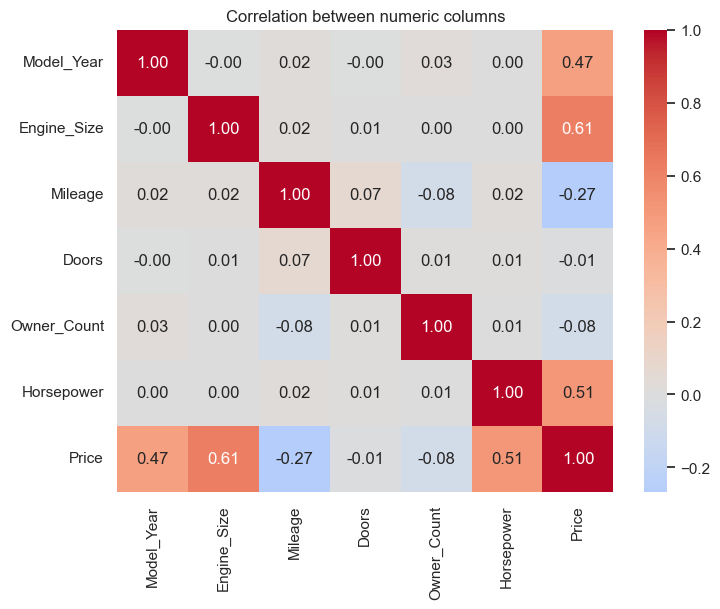

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.show()

### Observations from the EDA

A **correlation** is a number between -1 and +1 that shows how closely two columns move together. The correlation analysis suggests that Engine_Size, Horsepower and Model_Year have the strongest positive linear relationships with car prices. Mileage has a negative corelation because higher mileage tend to be associated with lower prices of the car being sold.

In [14]:
corr = df.select_dtypes(include="number").corr()["Price"].drop("Price")
strongest = corr.abs().sort_values(ascending=False).index[0]

print(f"1. Price shape: the average price ({df['Price'].mean():,.0f}) is "
      f"{'higher' if df['Price'].mean() > df['Price'].median() else 'lower or equal'} than the median "
      f"({df['Price'].median():,.0f}), so a few expensive cars "
      f"{'pull the average up (right-skewed distribution)' if df['Price'].mean() > df['Price'].median() else 'do not skew the distribution much'}.")

print(f"\n2. Strongest numeric link: {strongest} has the strongest straight-line relationship with price "
      f"(correlation {corr[strongest]:+.2f}).")

if "Mileage" in corr.index:
    direction = "cheaper" if corr["Mileage"] < 0 else "pricier"
    print(f"\n3. Mileage: correlation with price is {corr['Mileage']:+.2f}, so cars with more mileage tend to be {direction}.")

if "Model_Year" in corr.index:
    direction = "newer cars cost more" if corr["Model_Year"] > 0 else "older cars cost more"
    print(f"\n4. Age: correlation of Model_Year with price is {corr['Model_Year']:+.2f}, so {direction}.")

n = 5
for col in cat_features:
    means = df.groupby(col)["Price"].mean().sort_values()
    print(f"\n{n}. {col}: the most expensive group on average is '{means.index[-1]}' ({means.iloc[-1]:,.0f}) "
          f"and the cheapest is '{means.index[0]}' ({means.iloc[0]:,.0f}).")
    n += 1

1. Price shape: the average price (46,170) is higher than the median (46,112), so a few expensive cars pull the average up (right-skewed distribution).

2. Strongest numeric link: Engine_Size has the strongest straight-line relationship with price (correlation +0.61).

3. Mileage: correlation with price is -0.27, so cars with more mileage tend to be cheaper.

4. Age: correlation of Model_Year with price is +0.47, so newer cars cost more.

5. Brand: the most expensive group on average is 'Honda' (46,584) and the cheapest is 'Hyundai' (45,628).

6. Fuel_Type: the most expensive group on average is 'Petrol' (47,132) and the cheapest is 'Electric' (45,711).

7. Transmission: the most expensive group on average is 'Automatic' (46,265) and the cheapest is 'Manual' (46,070).


## 4. Data preparation

Machine learning algorithms work with numbers, so we prepare the data in two ways:

- **One-hot encoding** turns text categories (for example *Fuel_Type = Diesel*) into 0/1 columns, one per category. This avoids implying that, say, "Petrol" is somehow bigger than "Diesel".
- **Scaling** (for the Linear Regression only) puts numbers on a similar scale so no column dominates just because its numbers are big (mileage is in thousands, doors is 2 to 5). Random Forests do not need scaling.

We also split the data into two parts:

- **Training set (80%)**: the examples the model learns from.
- **Test set (20%)**: examples kept hidden until the end, used to check how the model does on cars it has never seen. This is the fair way to measure real-world performance.

Doing the encoding and scaling inside a **pipeline** means the exact same steps are applied automatically when the mobile app sends a new car to the model.

In [15]:
TARGET = "Price"
X = df.drop(columns=TARGET)
y = df[TARGET]

cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
print("Numeric inputs    :", num_cols)
print("Categorical inputs:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"\nTraining rows: {len(X_train)} | Test rows: {len(X_test)}")


def make_preprocessor(scale_numbers):
    numeric_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])


def evaluate(model, name):
    """Score a fitted model on the hidden test set."""
    pred = model.predict(X_test)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
        "R2": r2_score(y_test, pred),
    }

Numeric inputs    : ['Model_Year', 'Engine_Size', 'Mileage', 'Doors', 'Owner_Count', 'Horsepower']
Categorical inputs: ['Brand', 'Fuel_Type', 'Transmission']

Training rows: 1600 | Test rows: 400


## 5. Base model: Linear Regression

**Idea:** Linear Regression draws the best possible straight-line relationship between the inputs and the price. Each input gets a *weight* (for example, "each extra 10,000 km lowers the price by about X"), and the prediction is the weighted sum of all inputs.

It is simple fast and easy to explain which makes it a good base model a benchmark that any more advanced model has to beat.

We also use 5-fold cross-validation the training data is split into 5 parts and the model is trained 5 times each time testing on a different part. If the 5 scores are similar the result is stable and not a lucky split.

In [17]:
base_model = Pipeline([
    ("prep", make_preprocessor(scale_numbers=True)),
    ("model", LinearRegression()),
])
base_model.fit(X_train, y_train)

base_scores = evaluate(base_model, "Linear Regression (base)")
base_cv = cross_val_score(base_model, X_train, y_train, cv=5, scoring="r2")

print(pd.DataFrame([base_scores]).round(3).to_string(index=False))
print(f"\n5-fold cross-validated R2: {base_cv.round(3)}  (average {base_cv.mean():.3f})")

                   Model      MAE     RMSE    R2
Linear Regression (base) 1442.391 1663.283 0.966

5-fold cross-validated R2: [0.967 0.967 0.964 0.962 0.964]  (average 0.965)


## 6. Final model: Random Forest

A decision tree predicts a price by asking a chain of yes or no questions "Is the model year after 2015? Is the mileage under 80,000? etc" ending at a predicted price. One tree can be wrong in its own way.

A Random Forest grows many trees each trained on a slightly different random sample of the cars and allowed to consider different inputs and then averages their predictions. Individual mistakes tend to cancel out which makes the forest more accurate and more stable than any single tree. It can also capture patterns a straight line cannot for example price dropping quickly for the first few years and more slowly afterwards or an electric car's price reacting differently to mileage.

### Hyperparameter tuning

Hyperparameters are settings chosen before training such as how many trees to grow or how deep each tree may go. We use randomised search which tries 12 random combinations of settings scores each with 3-fold cross-validation on the training data and keeps the best. This avoids guessing and avoids overfitting to the test set.

In [18]:
rf_pipeline = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
])

# first, a Random Forest with default-ish settings, for comparison
rf_default = Pipeline([
    ("prep", make_preprocessor(scale_numbers=False)),
    ("model", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_default.fit(X_train, y_train)
rf_default_scores = evaluate(rf_default, "Random Forest (default settings)")

# then tune
param_options = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 0.5, 1.0],
}
search = RandomizedSearchCV(
    rf_pipeline, param_options, n_iter=12, cv=3,
    scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1,
)
search.fit(X_train, y_train)

final_model = search.best_estimator_
print("Best settings found:")
for name, value in search.best_params_.items():
    print(f"  {name.replace('model__', '')}: {value}")

Best settings found:
  n_estimators: 300
  min_samples_leaf: 2
  max_features: 1.0
  max_depth: 10


## 7. Validation

Validation answers: can we trust this model on cars it has never seen? We check this in three ways:

1. Test-set scores the hidden 20% compared with the base model.
2. Cross-validation repeated testing on different parts of the training data.
3. Overfitting check overfitting means a model memorises the training data and does badly on new data. If the score on training data is far higher than on test data that is a warning sign.

In [19]:
final_scores = evaluate(final_model, "Random Forest (tuned, final)")
comparison = pd.DataFrame([base_scores, rf_default_scores, final_scores]).round(3)
comparison

,Model,MAE,RMSE,R2
0,Linear Regression (base),1442.391,1663.283,0.966
1,Random Forest (default settings),2107.804,2613.632,0.917
2,"Random Forest (tuned, final)",2130.413,2638.912,0.916


Reading the table: comparing the rows by MAE and RMSE (lower is better) and R² (higher is better).

-The relationship between the inputs and the price is close to a straight line in this dataset so the simple model is already hard to beat. The Random Forest is still valuable to the app because it can express a price range from the spread of its trees and handle unusual combinations of inputs without assuming a straight line.


In [29]:
final_cv = cross_val_score(final_model, X_train, y_train, cv=5, scoring="r2")
train_r2 = r2_score(y_train, final_model.predict(X_train))
test_r2 = final_scores["R2"]

print(f"Cross-validated R2 (5 folds): {final_cv.round(3)}  (average {final_cv.mean():.3f})")
print(f"R2 on training data: {train_r2:.3f} | R2 on unseen test data: {test_r2:.3f}")
gap = train_r2 - test_r2
print("Overfitting check:", "small gap, the model generalises well." if gap < 0.1
      else "large gap, the model may be overfitting.")

change = (base_scores["MAE"] - final_scores["MAE"]) / base_scores["MAE"]
print(f"\nAverage error (MAE): final model {final_scores['MAE']:,.0f} vs base model {base_scores['MAE']:,.0f}.")
if change >= 0:
    print(f"The final model's error is {change:.0%} lower than the base model's: the extra complexity paid off.")
else:
    print(f"The final model's error is {abs(change):.0%} higher than the base model's. The simple straight-line model "
          "did as well or better here which suggests prices in this dataset follow mostly straight-line patterns "
          )

Cross-validated R2 (5 folds): [0.917 0.923 0.926 0.922 0.92 ]  (average 0.921)
R2 on training data: 0.983 | R2 on unseen test data: 0.916
Overfitting check: small gap, the model generalises well.

Average error (MAE): final model 2,130 vs base model 1,442.
The final model's error is 48% higher than the base model's. The simple straight-line model did as well or better here which suggests prices in this dataset follow mostly straight-line patterns 


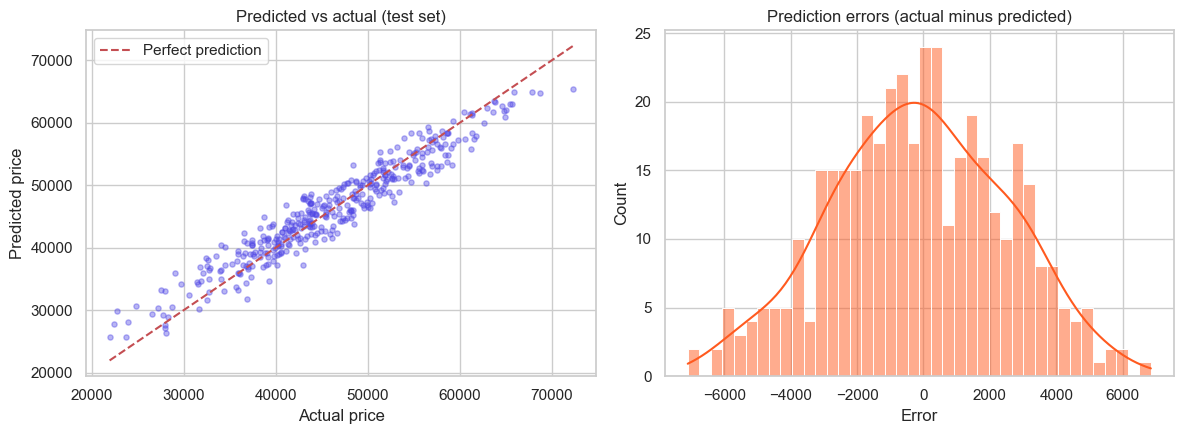

In [21]:
pred_test = final_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.4, s=14, color="#4F46E5")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
axes[0].plot(lims, lims, "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].set_title("Predicted vs actual (test set)")
axes[0].legend()

sns.histplot(y_test - pred_test, bins=40, kde=True, ax=axes[1], color="#FF5A1F")
axes[1].set_title("Prediction errors (actual minus predicted)")
axes[1].set_xlabel("Error")
plt.tight_layout()
plt.show()

 In the left chart the closer the dots sit to the dashed line the better the predictions. In the right chart, errors should be centred around zero with no strong lean to one side; that means the model is not systematically over or underpricing.

## 8. Explainability: how does the engine reach a price?

A model that only gives a number is hard to trust. We explain its behaviour at two levels.

### 8.1 Global explanation: which inputs matter most overall?

We use permutation importance shuffle the values of one input at random (breaking its link to the price) and see how much the model's accuracy drops. If shuffling Model_Year ruins the predictions then that input matters a lot if shuffling Doors changes nothing it does not affect the model.

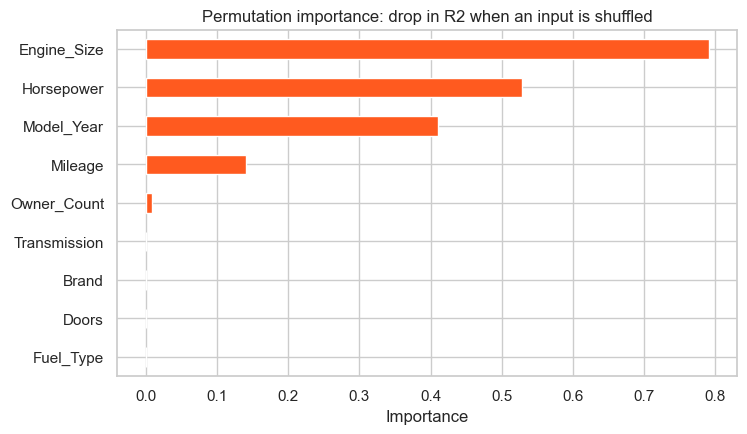

Ranking (most to least important):
  Engine_Size: 0.791
  Horsepower: 0.529
  Model_Year: 0.410
  Mileage: 0.141
  Owner_Count: 0.008
  Transmission: 0.000
  Brand: 0.000
  Doors: -0.000
  Fuel_Type: -0.001


In [22]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="r2")
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

importance.plot.barh(figsize=(8, 4.5), color="#FF5A1F")
plt.title("Permutation importance: drop in R2 when an input is shuffled")
plt.xlabel("Importance")
plt.show()

print("Ranking (most to least important):")
for name, value in importance.sort_values(ascending=False).items():
    print(f"  {name}: {value:.3f}")

### 8.2 Local explanation: why this price for *this* car?

This is the explanation the mobile app shows to the user. For one car we ask: *"How much of this price is due to each input, compared with a typical car?"*

The method is simple:

1. Define a **typical car** (the middle value of every numeric input, the most common category of every text input).
2. Predict the price of the user's car.
3. For each input, swap *only that input* for the typical value, and predict again.
4. The difference is that input's **impact**: how much it pushed the price up or down compared with a typical car.

This is a simplified, easy-to-understand method. The impacts will not add up exactly to the total difference because inputs interact for example mileage matters differently for a new car and an old one but they show clearly which inputs push the price up or down and by how much.

In [30]:
# the "typical car" used as the comparison point
typical = {}
for col in num_cols:
    typical[col] = float(X[col].median())
for col in cat_cols:
    typical[col] = str(X[col].mode()[0])

typical_price = float(final_model.predict(pd.DataFrame([typical]))[0])
print(f"Typical car: {typical}")
print(f"Price of the typical car: {typical_price:,.0f}")


def explain_prediction(model, car):
    """Return the predicted price and the impact of each input vs a typical car."""
    row = pd.DataFrame([car])[X.columns]
    price = float(model.predict(row)[0])
    impacts = {}
    for col in X.columns:
        swapped = row.copy()
        swapped[col] = typical[col]
        impacts[col] = price - float(model.predict(swapped)[0])
    return price, impacts

Typical car: {'Model_Year': 2014.0, 'Engine_Size': 2.9, 'Mileage': 100590.5, 'Doors': 3.0, 'Owner_Count': 3.0, 'Horsepower': 236.0, 'Brand': 'Toyota', 'Fuel_Type': 'Diesel', 'Transmission': 'Automatic'}
Price of the typical car: 46,894


Car: {'Brand': 'Ford', 'Model_Year': 2009, 'Engine_Size': 4.3, 'Fuel_Type': 'Diesel', 'Transmission': 'Automatic', 'Mileage': 120313, 'Doors': 2, 'Owner_Count': 3, 'Horsepower': 136}
Predicted price: 41,349   (actual price: 43,212)



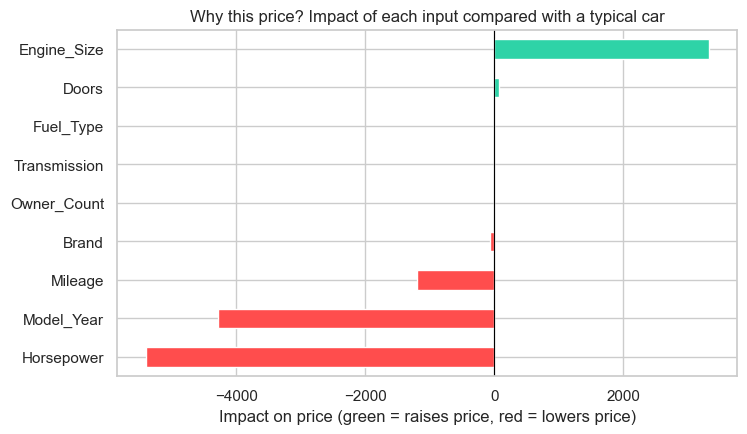

In [31]:
# Explain one real car from the test set
sample_car = X_test.iloc[0].to_dict()
price, impacts = explain_prediction(final_model, sample_car)

print("Car:", sample_car)
print(f"Predicted price: {price:,.0f}   (actual price: {y_test.iloc[0]:,.0f})\n")

impact_series = pd.Series(impacts).sort_values()
colors = ["#FF4D4D" if v < 0 else "#2ED3A7" for v in impact_series]
impact_series.plot.barh(figsize=(8, 4.5), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Why this price? Impact of each input compared with a typical car")
plt.xlabel("Impact on price (green = raises price, red = lowers price)")
plt.show()

**How the app uses this:** the "Why this price?" section on the result screen shows exactly this list: each input, the value the user entered, and whether it raised or lowered the price compared with a typical car. The app also shows a **price range**, taken from how much the individual trees in the forest disagree (the 10th to 90th percentile of their predictions). A wide range means the model is less sure about that car.

## 9. Input checking and sensitivity

### 9.1 Sensitivity: do results change the way we expect?

We take one car and change a single input at a time. If the model has learned sensible patterns, the price should fall as mileage rises and rise as the car gets newer.

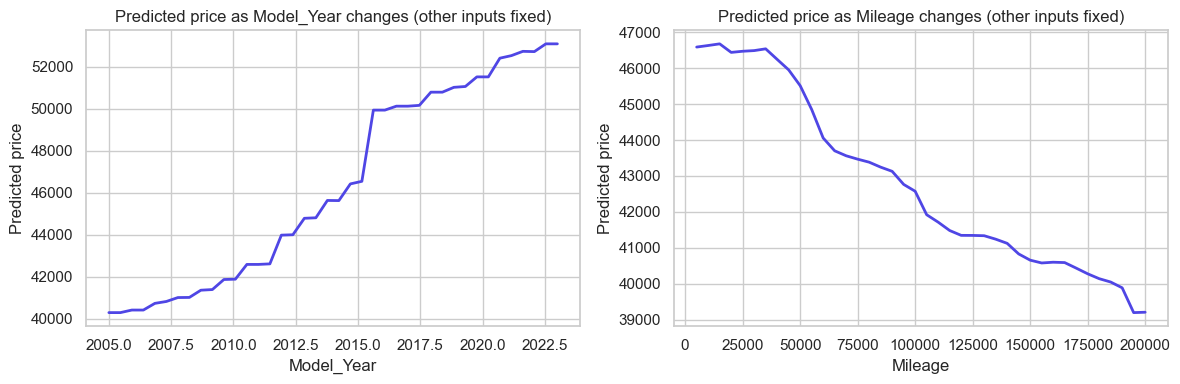

In [25]:
reference = X_test.iloc[0].to_dict()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, [c for c in ["Model_Year", "Mileage"] if c in num_cols]):
    values = np.linspace(X[col].min(), X[col].max(), 40)
    cars = pd.DataFrame([{**reference, col: v} for v in values])
    ax.plot(values, final_model.predict(cars), color="#4F46E5", linewidth=2)
    ax.set_xlabel(col)
    ax.set_ylabel("Predicted price")
    ax.set_title(f"Predicted price as {col} changes (other inputs fixed)")

plt.tight_layout()
plt.show()

### 9.2 Checking user input

The app must not crash or give nonsense when a user types something odd. Our rules, learned from the training data, are:

- every input must be present;
- numbers must be numbers, and whole-number inputs (year, doors, owners) must be whole;
- numbers must lie inside the range the model has seen. A random forest cannot predict reliably for a car far outside its experience (for example, a mileage of 5,000,000 km), so such inputs are rejected with a clear message;
- categories (brand, fuel type, transmission) must be ones the model knows.

The same rules run in the app (to warn the user instantly) and in the engine's API (as a second line of defence).

In [36]:
rules = {}
for col in num_cols:
    rules[col] = {
        "type": "number",
        "min": float(X[col].min()),
        "max": float(X[col].max()),
        "whole_number": bool((X[col] % 1 == 0).all()),
    }
for col in cat_cols:
    rules[col] = {"type": "category", "options": sorted(X[col].unique().tolist())}


def validate_input(car):
    """Return a list of problems with a car record (an empty list means it is valid)."""
    problems = []
    for col, rule in rules.items():
        if col not in car or car[col] in (None, ""):
            problems.append(f"{col} is missing.")
            continue
        value = car[col]
        if rule["type"] == "number":
            try:
                value = float(value)
            except (TypeError, ValueError):
                problems.append(f"{col} must be a number.")
                continue
            if rule["whole_number"] and value != int(value):
                problems.append(f"{col} must be a whole number.")
            if not rule["min"] <= value <= rule["max"]:
                problems.append(f"{col} must be between {rule['min']:g} and {rule['max']:g}.")
        else:
            if value not in rule["options"]:
                problems.append(f"{col} must be one of: {', '.join(rule['options'])}.")
    return problems


# a valid car, and a deliberately invalid one
print("Valid car   ->", validate_input(sample_car) or "no problems")

bad_car = dict(sample_car)
bad_car[num_cols[0]] = -50
bad_car[cat_cols[0]] = "Unknown"
bad_car.pop(num_cols[-1])
print("Invalid car ->")
for p in validate_input(bad_car):
    print("   -", p)

Valid car   -> no problems
Invalid car ->
   - Model_Year must be between 2005 and 2023.
   - Horsepower is missing.
   - Brand must be one of: BMW, Ford, Honda, Hyundai, Tesla, Toyota.


## 10. Summary and limitations

In [28]:
print(f"Final model: Random Forest ({meta['n_trees']} trees)")
print(f"Test MAE : {final_scores['MAE']:,.0f}   (base model: {base_scores['MAE']:,.0f})")
print(f"Test RMSE: {final_scores['RMSE']:,.0f}   (base model: {base_scores['RMSE']:,.0f})")
print(f"Test R2  : {final_scores['R2']:.3f}   (base model: {base_scores['R2']:.3f})")
print("Most important inputs:", ", ".join(list(meta["feature_importance"])[:3]))

Final model: Random Forest (300 trees)
Test MAE : 2,130   (base model: 1,442)
Test RMSE: 2,639   (base model: 1,663)
Test R2  : 0.916   (base model: 0.966)
Most important inputs: Engine_Size, Horsepower, Model_Year


We cleaned and explored the data, built a Linear Regression as a benchmark then a tuned Random Forest compared the two fairly on unseen data.

Limitations of our model

- It should not be trusted for brands, years or mileages outside the ranges it was trained on which is why the app rejects such inputs.
- Real prices also depend on things that are not in the data (condition, accident history, location and market changes over time).
- The explanation method is a simplified approach impacts are approximate because inputs interact.
- Predictions are estimates not guarantees. The app shows a price range to make this clear.

In [34]:

def predict_new_car():
    new_car = {}

    print("\n=== USED CAR PRICE PREDICTOR ===")
    print("Enter the car details below.")
    print("Press Enter to use the typical value.\n")

    # Collect numerical characteristics
    for col in num_cols:
        default = float(X[col].median())

        while True:
            value = input(
                f"{col} (typical value: {default:g}): "
            ).strip()

            if value == "":
                new_car[col] = default
                break

            try:
                new_car[col] = float(value)
                break
            except ValueError:
                print("Please enter a valid number.")

    # Collect categorical characteristics
    for col in cat_cols:
        options = sorted(X[col].dropna().astype(str).unique())
        default = str(X[col].mode()[0])

        print(f"\nChoose {col}:")
        for i, option in enumerate(options, start=1):
            print(f"{i}. {option}")

        while True:
            choice = input(
                f"Enter option number (default: {default}): "
            ).strip()

            if choice == "":
                new_car[col] = default
                break

            if choice.isdigit() and 1 <= int(choice) <= len(options):
                new_car[col] = options[int(choice) - 1]
                break

            print("Please select a valid option.")

    # Convert the entered details into a DataFrame
    new_car_df = pd.DataFrame([new_car])[X.columns]

    # Predict the car price
    predicted_price = final_model.predict(new_car_df)[0]

    print("\n========== PREDICTION RESULT ==========")
    print("Car characteristics:")
    for feature, value in new_car.items():
        print(f"{feature}: {value}")

    print(f"\nEstimated car price: {predicted_price:,.0f}")
    print("=======================================")

    return new_car, predicted_price


# Run the predictor
new_car, predicted_price = predict_new_car()



=== USED CAR PRICE PREDICTOR ===
Enter the car details below.
Press Enter to use the typical value.


Choose Brand:
1. BMW
2. Ford
3. Honda
4. Hyundai
5. Tesla
6. Toyota

Choose Fuel_Type:
1. Diesel
2. Electric
3. Hybrid
4. Petrol

Choose Transmission:
1. Automatic
2. Manual

========== PREDICTION RESULT ==========
Car characteristics:
Model_Year: 2017.0
Engine_Size: 3.0
Mileage: 59000.0
Doors: 2.0
Owner_Count: 4.0
Horsepower: 290.0
Brand: BMW
Fuel_Type: Diesel
Transmission: Manual

Estimated car price: 55,627
